# Linear Regression for Sugarcane Irrigation Prediction

AI-Based Irrigation Advisory System for Sugarcane

## Objective
Predict the continuous irrigation requirement, `drip_liters_per_day`, in configured units of **liters/day**. This is regression; no binary irrigation label or arbitrary threshold is created.

## Why this model?
Linear regression models a linear relationship using weighted features and an intercept: ŷ = β0 + β1x1 + β2x2 + ... + βpxp. It is a fast, interpretable baseline.

## Imports and reproducibility
Run from the repository root or its `notebooks/` directory. Install `requirements-notebooks.txt` first. The shared project modules determine feature selection, preprocessing, and splits.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists() and (p / "src/models/common.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run inside the sugarcane-irrigation-ml repository")
sys.path.insert(0, str(ROOT))
from src.config import load_config, resolve_path
from src.data.merge_data import infer_date_column
from src.features.build_features import select_feature_columns, assert_no_target_leakage
from src.models.common import build_preprocessor, make_holdout_splits, combine_train_validation
cfg = load_config()
RANDOM_STATE = int(cfg["random_seed"])
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True})
MODEL_KEY = 'linear_regression'

Matplotlib is building the font cache; this may take a moment.


## Load the real project dataset
The primary source is the **Sugarcane Irrigation Dataset for the SIDSS Framework**, associated with **NIT Patna**. **NASA POWER is mandatory**. We reuse the processed merged CSV and cached weather; these notebooks make no API calls. If the processed file is absent, run `python main.py` once first.

The project cleans duplicates and invalid targets, clips numeric input outliers at the 1st/99th percentiles, merges NASA weather, and builds features before saving this CSV. Existing global clipping uses the full dataset before splitting: that is a preprocessing leakage limitation retained for parity, not a claim of fully independent preprocessing.

In [2]:
data_path = resolve_path(cfg["data"]["processed_path"])
df = pd.read_csv(data_path)
TARGET = cfg["targets"]["regression_target"]
UNIT = cfg["targets"]["water_unit"]
weather_columns = ["temperature_mean", "temperature_min", "temperature_max", "relative_humidity", "rainfall", "wind_speed", "solar_radiation", "surface_pressure"]
assert set(weather_columns).issubset(df.columns), "Mandatory NASA weather features missing"
assert df[weather_columns].notna().all().all()
print("Dataset SHA256:", hashlib.sha256(data_path.read_bytes()).hexdigest())
display(df.head())
print("Shape:", df.shape, "Rows:", len(df), "Columns:", len(df.columns), "Target:", TARGET)
df.info()
display(df.isna().sum().rename("missing_values").to_frame())

Dataset SHA256: e686d3ea8262bb01f2dd3580ae0e5a6f62ed5bc87eee5e72b3d993b6ca6b7a04


,inputleaf,stomataopenclose,nitrogen,chloropyll,phosphorus,leafhumidity,leafevaporation,evapotranspiration,stages,soilph,...,temperature_mean,temperature_min,temperature_max,relative_humidity,rainfall,wind_speed,solar_radiation,surface_pressure,temperature_range,rainfall_indicator
0,leaf_1,0.437086,2.557245,46.908120,0.439720,82.688993,1.585756,5.654312,germination,6.890814,...,26.025205,20.503589,32.424712,59.869233,2.946603,2.11137,15.839616,100.090137,11.921123,1
1,leaf_2,0.955643,2.437546,51.867256,0.405483,66.033523,2.165787,4.101442,maturity,6.005485,...,26.025205,20.503589,32.424712,59.869233,2.946603,2.11137,15.839616,100.090137,11.921123,1
2,leaf_3,0.758795,1.076926,30.018716,0.315274,90.533810,0.750178,4.899641,grandgrowth,6.122811,...,26.025205,20.503589,32.424712,59.869233,2.946603,2.11137,15.839616,100.090137,11.921123,1
3,leaf_4,0.638793,2.023743,44.994964,0.204285,81.459068,0.759566,3.744193,germination,5.742163,...,26.025205,20.503589,32.424712,59.869233,2.946603,2.11137,15.839616,100.090137,11.921123,1
4,leaf_5,0.240417,2.140587,42.869839,0.398496,65.502136,1.613637,4.520138,germination,7.229318,...,26.025205,20.503589,32.424712,59.869233,2.946603,2.11137,15.839616,100.090137,11.921123,1


Shape: (1500, 28) Rows: 1500 Columns: 28 Target: drip_liters_per_day
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   inputleaf                       1500 non-null   str    
 1   stomataopenclose                1500 non-null   float64
 2   nitrogen                        1500 non-null   float64
 3   chloropyll                      1500 non-null   float64
 4   phosphorus                      1500 non-null   float64
 5   leafhumidity                    1500 non-null   float64
 6   leafevaporation                 1500 non-null   float64
 7   evapotranspiration              1500 non-null   float64
 8   stages                          1500 non-null   str    
 9   soilph                          1500 non-null   float64
 10  soilhumidity                    1500 non-null   float64
 11  microclimatictemp               1500 

,missing_values
inputleaf,0
stomataopenclose,0
nitrogen,0
chloropyll,0
phosphorus,0
leafhumidity,0
leafevaporation,0
evapotranspiration,0
stages,0
soilph,0


## Explain the data
Soil/nutrient features include `soilph`, `soilhumidity`, `nitrogen`, and `phosphorus`. Crop/plant fields include `inputleaf`, `stomataopenclose`, `chloropyll`, `leafhumidity`, `leafevaporation`, `evapotranspiration`, `stages`, and `yield_kg_per_plant`. Local climate fields are `microclimatictemp`, `microclimaticseason`, and `microclimaticwindspeed`. NASA columns are listed below; derived weather features are `temperature_range` and `rainfall_indicator`.

The source has no row-level dates or coordinates. NASA daily values for 2025 at the configured NIT Patna coordinates are averaged and repeated across rows. Constant weather columns cannot explain differences between samples. `inputleaf` may encode identity and `yield_kg_per_plant` may be unavailable at advisory time; their inclusion follows the main project, but field deployment requires an availability audit. Target magnitudes are unusually large for liters/day; units and measurement provenance need validation before operational use.

In [3]:
display(df[weather_columns].nunique().rename("unique_values").to_frame())

,unique_values
temperature_mean,1
temperature_min,1
temperature_max,1
relative_humidity,1
rainfall,1
wind_speed,1
solar_radiation,1
surface_pressure,1


## Target and leakage check
Exclude the actual target, `predicted_water_liters_per_day`, `predicted_yield`, and other target-like columns using the shared selector. These checks identify known direct leakage, not all possible scientific confounding.

In [4]:
date_column = infer_date_column(df, cfg.get("schema", {}).get("date_column"))
feature_columns = select_feature_columns(df, TARGET, date_column)
assert_no_target_leakage(feature_columns, TARGET)
known_leakage = {TARGET, "predicted_water_liters_per_day", "predicted_yield"}
assert known_leakage.isdisjoint(feature_columns)
X = df.loc[:, feature_columns]
y = df[TARGET]
print("Target:", TARGET, "Unit:", UNIT)
print("Excluded:", sorted(set(df.columns) - set(feature_columns)))
print("Ordered feature set:", feature_columns)
display(y.describe())

Target: drip_liters_per_day Unit: liters/day
Excluded: ['drip_liters_per_day', 'predicted_water_liters_per_day', 'predicted_yield']
Ordered feature set: ['inputleaf', 'stomataopenclose', 'nitrogen', 'chloropyll', 'phosphorus', 'leafhumidity', 'leafevaporation', 'evapotranspiration', 'stages', 'soilph', 'soilhumidity', 'microclimatictemp', 'microclimaticseason', 'microclimaticwindspeed', 'yield_kg_per_plant', 'temperature_mean', 'temperature_min', 'temperature_max', 'relative_humidity', 'rainfall', 'wind_speed', 'solar_radiation', 'surface_pressure', 'temperature_range', 'rainfall_indicator']


count    1.500000e+03
mean     2.135899e+09
std      3.142995e+09
min      1.296784e+07
25%      4.547497e+08
50%      1.112379e+09
75%      2.433338e+09
max      3.675053e+10
Name: drip_liters_per_day, dtype: float64

## Shared train/validation/test split
The main project makes a seeded 60% training / 20% validation / 20% test split. It then combines training and validation for cross-validation and final refitting (80%), keeping the final 20% test set outside tuning. We reproduce that exact index order. A temporal dataset would use the shared chronological split instead. No parameters are selected using notebook test results.

In [5]:
train_cfg = cfg["training"]
temporal_order = pd.to_datetime(df[date_column]) if date_column else None
splits = make_holdout_splits(X, y, test_size=float(train_cfg["test_size"]), validation_size=float(train_cfg["validation_size"]), random_seed=RANDOM_STATE, temporal_order=temporal_order)
X_train, y_train = combine_train_validation(splits)
X_test, y_test = splits.X_test, splits.y_test
assert set(X_train.index).isdisjoint(X_test.index)
print("Initial train/validation/test:", len(splits.X_train), len(splits.X_val), len(X_test))
print("Final fit/test shapes:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("Test index SHA256:", hashlib.sha256(X_test.index.to_numpy().tobytes()).hexdigest())

Initial train/validation/test: 900 300 300
Final fit/test shapes: (1200, 25) (300, 25) (1200,) (300,)
Test index SHA256: 77741f9c4ccda6eadafb64bf581012488584d1bd73e2c90688ffc58bc09d0a0b


## Preprocessing
The shared `ColumnTransformer` median-imputes numeric features and mode-imputes categorical features, then one-hot encodes categories with unknown values ignored. Feature order is preserved by the transformer and recovered after fitting. All fitted imputation/encoding parameters use the final fit subset only. Numeric features are standardized for this linear baseline, as in the main project.

In [6]:
preprocessor = build_preprocessor(X, scale_numeric=True)

## Model creation and actual saved hyperparameters
We instantiate only this notebook’s model family and read the selected parameters from `reports/metrics/regressor_results.json`. The original tree searches used seeded `RandomizedSearchCV`, 8 candidate draws, 3 shuffled KFold folds, and negative RMSE on the combined training/validation subset. Linear Regression had no search. Search spaces are documented in `src/models/train_regressors.py`. This notebook refits the selected configuration rather than inventing or rerunning tuning results.

In [7]:
saved_results = json.loads((ROOT / "reports/metrics/regressor_results.json").read_text())
record = saved_results[MODEL_KEY]
model = LinearRegression()
pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
pipeline.set_params(**record["best_params"])
print("Saved best parameters:", record["best_params"])
print("Saved CV score (negative RMSE; NaN means no search):", record["cv_score"])
display(pd.Series(model.get_params(), name="value").to_frame())

Saved best parameters: {}
Saved CV score (negative RMSE; NaN means no search): nan


,value
copy_X,True
fit_intercept,True
n_jobs,None
positive,False
tol,0.000001


## Train the model
Fit the entire preprocessing and regression pipeline on the shared final fit subset.

In [8]:
pipeline.fit(X_train, y_train)
print("Training complete")

Training complete


## Predict on the held-out test set

In [9]:
y_pred = pipeline.predict(X_test)
comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred, "Absolute Error": np.abs(y_test - y_pred)})
display(comparison.head(10))

,Actual,Predicted,Absolute Error
1116,1.049335e+09,2.890267e+09,1.840932e+09
1368,8.715676e+08,1.361401e+09,4.898334e+08
422,6.376669e+08,1.034231e+09,3.965646e+08
413,2.009941e+08,-1.908595e+09,2.109589e+09
451,1.251243e+09,1.968051e+09,7.168074e+08
861,7.395599e+08,4.417696e+08,2.977903e+08
1063,8.038606e+08,9.873640e+08,1.835034e+08
741,7.449437e+07,-1.410719e+09,1.485214e+09
1272,2.510838e+09,3.208810e+09,6.979714e+08
259,1.028210e+08,-1.675975e+09,1.778796e+09


## Evaluate
**MAE** is the average absolute prediction error. **RMSE** penalizes large errors more strongly. Both use the target unit. **R²** measures variation explained relative to predicting the test target mean; it can be negative and is not accuracy. Saved-run comparisons below expose any environment or CSV round-trip differences.

In [10]:
metrics = {"mae": float(mean_absolute_error(y_test, y_pred)), "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))), "r2": float(r2_score(y_test, y_pred))}
metric_comparison = pd.DataFrame({"Notebook": metrics, "Saved project run": record["test_metrics"]})
metric_comparison["Difference"] = metric_comparison["Notebook"] - metric_comparison["Saved project run"]
display(metric_comparison)
assert np.isfinite(list(metrics.values())).all()

,Notebook,Saved project run,Difference
mae,1.241976e+09,1.241976e+09,-2.384186e-07
rmse,1.861024e+09,1.861024e+09,-4.768372e-07
r2,6.079456e-01,6.079456e-01,1.110223e-16


## Prediction and residual diagnostics
The diagonal indicates perfect predictions. Residuals are actual minus predicted: positive values mean underprediction. Look for systematic patterns and extreme errors; these plots do not establish causality.

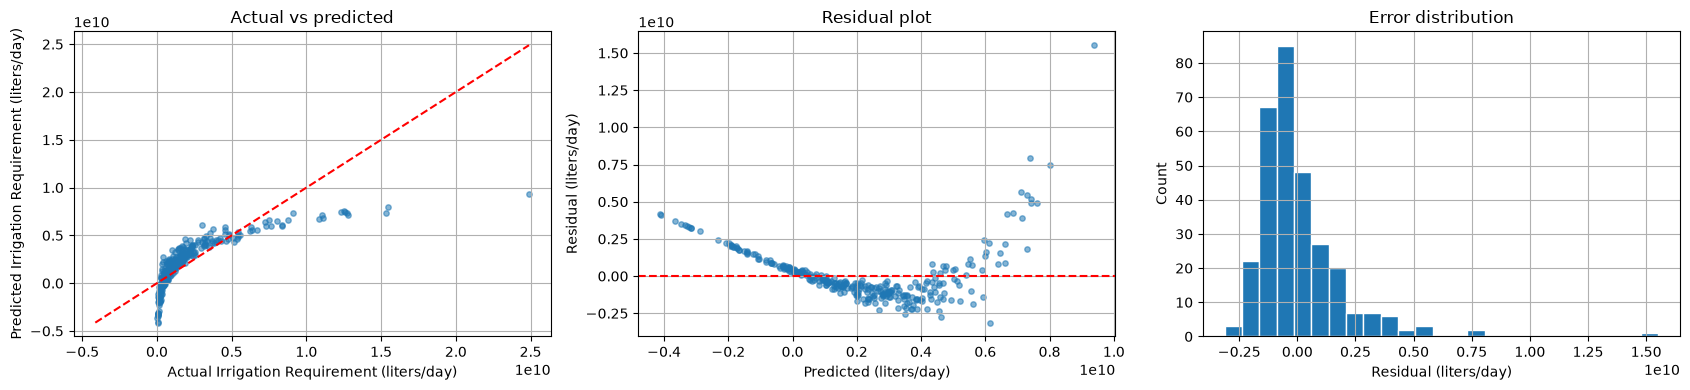

In [11]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(y_test, y_pred, alpha=0.55, s=15)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
axes[0].plot([lo, hi], [lo, hi], "r--")
axes[0].set(xlabel=f"Actual Irrigation Requirement ({UNIT})", ylabel=f"Predicted Irrigation Requirement ({UNIT})", title="Actual vs predicted")
axes[1].scatter(y_pred, residuals, alpha=0.55, s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel=f"Predicted ({UNIT})", ylabel=f"Residual ({UNIT})", title="Residual plot")
axes[2].hist(residuals, bins=25, edgecolor="white")
axes[2].set(xlabel=f"Residual ({UNIT})", ylabel="Count", title="Error distribution")
fig.tight_layout()
plt.show()

## Model-specific interpretation
Importances describe the fitted model, not causal effects. Encoded features are shown individually, so a categorical field can contribute through multiple columns.

In [12]:
feature_names = pipeline.named_steps["preprocess"].get_feature_names_out()
fitted_model = pipeline.named_steps["model"]

Numeric coefficients represent a one-standard-deviation change in the input, holding other inputs fixed. One-hot coefficients depend on the encoding and collinearity; with all categories and an intercept, individual category coefficients are not uniquely causal or necessarily stable. Constant NASA columns provide no between-row signal.

,coefficient
numeric__stomataopenclose,5.202783e+08
numeric__nitrogen,8.291682e+08
numeric__chloropyll,6.374732e+08
numeric__phosphorus,6.792334e+08
numeric__leafhumidity,2.911296e+08
...,...
categorical__stages_maturity,6.842694e+06
categorical__stages_tillering,-1.342912e+08
categorical__microclimaticseason_monsoon,-1.385207e+08
categorical__microclimaticseason_summer,6.294179e+07


,top_positive
categorical__inputleaf_leaf_1304,2.626199e+10
categorical__inputleaf_leaf_1430,2.260802e+10
categorical__inputleaf_leaf_1488,1.846427e+10
categorical__inputleaf_leaf_201,1.540411e+10
categorical__inputleaf_leaf_1124,1.498578e+10
categorical__inputleaf_leaf_854,1.440765e+10
categorical__inputleaf_leaf_610,1.292124e+10
categorical__inputleaf_leaf_752,1.235785e+10
categorical__inputleaf_leaf_353,1.105702e+10
categorical__inputleaf_leaf_1255,1.047956e+10


,top_negative
categorical__inputleaf_leaf_117,-3.417634e+09
categorical__inputleaf_leaf_893,-3.189970e+09
categorical__inputleaf_leaf_841,-3.178502e+09
categorical__inputleaf_leaf_902,-3.003146e+09
categorical__inputleaf_leaf_455,-2.860718e+09
categorical__inputleaf_leaf_172,-2.747574e+09
categorical__inputleaf_leaf_985,-2.736361e+09
categorical__inputleaf_leaf_425,-2.709888e+09
categorical__inputleaf_leaf_733,-2.533518e+09
categorical__inputleaf_leaf_829,-2.496198e+09


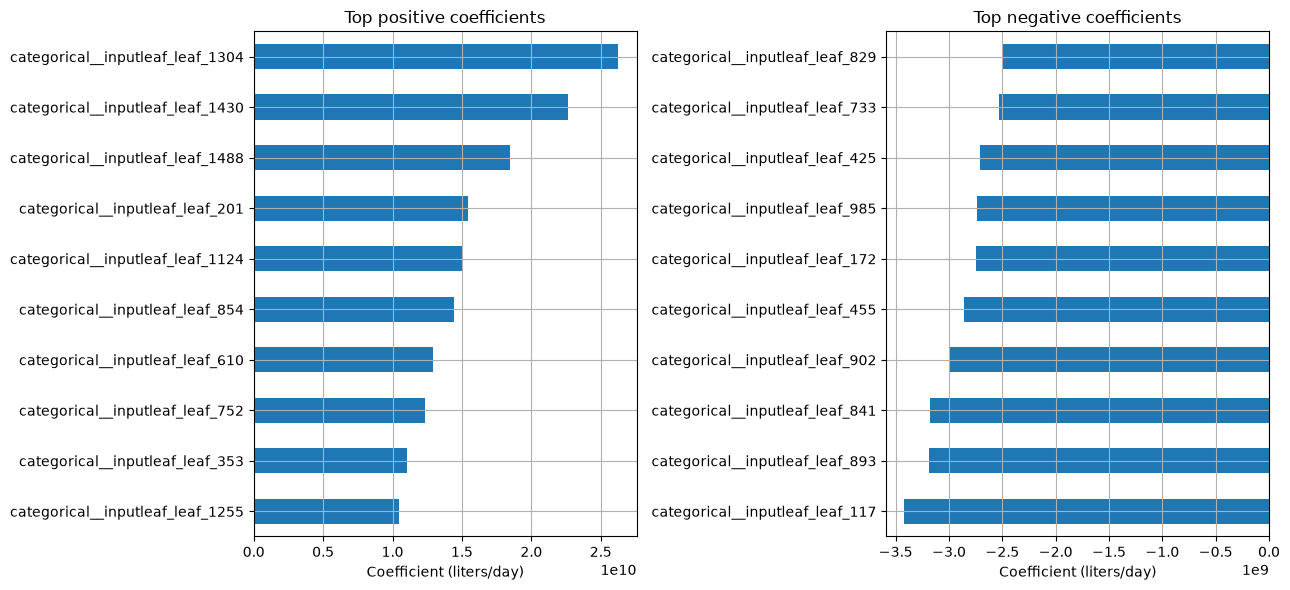

In [13]:
coefficients = pd.Series(fitted_model.coef_, index=feature_names, name="coefficient")
ranked = coefficients.abs().sort_values(ascending=False)
display(coefficients.to_frame())
positive = coefficients[coefficients > 0].nlargest(10)
negative = coefficients[coefficients < 0].nsmallest(10)
display(positive.rename("top_positive").to_frame(), negative.rename("top_negative").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for values, ax, title in [(positive, axes[0], "Top positive coefficients"), (negative, axes[1], "Top negative coefficients")]:
    if not values.empty:
        values.sort_values().plot.barh(ax=ax)
    ax.set_title(title)
    ax.set_xlabel(f"Coefficient ({UNIT})")
fig.tight_layout()
plt.show()

## One real test sample
This row comes directly from the held-out split; no synthetic input is introduced.

In [14]:
display(X_test.iloc[[0]].T.rename(columns={X_test.index[0]: "input_value"}))
display(comparison.iloc[[0]])

,input_value
inputleaf,leaf_1117
stomataopenclose,0.182338
nitrogen,2.080702
chloropyll,56.690723
phosphorus,0.550848
leafhumidity,88.153104
leafevaporation,2.416655
evapotranspiration,2.410138
stages,maturity
soilph,6.335046


,Actual,Predicted,Absolute Error
1116,1.049335e+09,2.890267e+09,1.840932e+09


## Interpretation of observed results

In [15]:
top_features = ", ".join(ranked.head(3).index)
relative_rmse = metrics["rmse"] / y_test.std()
display(Markdown(f"The held-out RMSE is **{metrics['rmse']:,.2f} {UNIT}**, or **{relative_rmse:.2f}** times the test target standard deviation. R² is **{metrics['r2']:.4f}**. The strongest fitted feature signals are **{top_features}**. These are predictive associations. Constant weather, global pre-split clipping, possible post-harvest yield information, and uncertain target magnitudes limit the conclusions. The main project also chose its overall winning model by test RMSE, so a separate external evaluation is needed for an unbiased assessment of that model selection."))

The held-out RMSE is **1,861,024,286.38 liters/day**, or **0.63** times the test target standard deviation. R² is **0.6079**. The strongest fitted feature signals are **categorical__inputleaf_leaf_1304, categorical__inputleaf_leaf_1430, categorical__inputleaf_leaf_1488**. These are predictive associations. Constant weather, global pre-split clipping, possible post-harvest yield information, and uncertain target magnitudes limit the conclusions. The main project also chose its overall winning model by test RMSE, so a separate external evaluation is needed for an unbiased assessment of that model selection.

## Advantages and limitations
**Main strengths:** Simple, interpretable, and fast.

**Model limitations:** Limited nonlinear modeling; sensitive to outliers and assumptions.

All results describe this shared dataset and split; they do not validate field irrigation recommendations.

In [16]:
summary = {"model": 'Linear Regression', "metrics": metrics, "top_features": top_features, "strength": 'Simple, interpretable, and fast', "limitation": 'Limited nonlinear modeling; sensitive to outliers and assumptions'}
display(Markdown(f"**Model:** {summary['model']}  \n**Test MAE:** {metrics['mae']:,.2f} {UNIT}  \n**Test RMSE:** {metrics['rmse']:,.2f} {UNIT}  \n**Test R²:** {metrics['r2']:.6f}  \n**Most important features:** {top_features}  \n**Main strength:** {summary['strength']}  \n**Main limitation:** {summary['limitation']}"))

**Model:** Linear Regression  
**Test MAE:** 1,241,975,701.84 liters/day  
**Test RMSE:** 1,861,024,286.38 liters/day  
**Test R²:** 0.607946  
**Most important features:** categorical__inputleaf_leaf_1304, categorical__inputleaf_leaf_1430, categorical__inputleaf_leaf_1488  
**Main strength:** Simple, interpretable, and fast  
**Main limitation:** Limited nonlinear modeling; sensitive to outliers and assumptions

## Final summary

**Model:** Linear Regression  
**Test MAE:** 1,241,975,701.84 liters/day  
**Test RMSE:** 1,861,024,286.38 liters/day  
**Test R²:** 0.607946  
**Most important features:** categorical__inputleaf_leaf_1304, categorical__inputleaf_leaf_1430, categorical__inputleaf_leaf_1488  
**Main strength:** Simple, interpretable, and fast  
**Main limitation:** Limited nonlinear modeling; sensitive to outliers and assumptions

This saved snapshot reflects the execution above; after manual reruns, the preceding dynamic summary is authoritative.